# 01 · Entendimento dos dados

**Objetivo:** conhecer a estrutura e a qualidade dos dados brutos e construir as séries diárias usadas em todo o projeto. Também verificar se `index_1.csv` e `index_2.csv` representam máquinas diferentes, o que condiciona a soma das duas no Total.

Toda a lógica está em `src/`. Este notebook só executa, exibe e interpreta.

| Seção | Conteúdo | Código |
|---|---|---|
| 1 | Carga, validação do contrato e padronização | `src/data/load_data.py`, `src/data/preprocessing.py` |
| 2 | Séries diárias: zero × ausente × máquina inexistente | `src/data/preprocessing.py` |
| 3 | `index_2` é outra máquina? (testes reaproveitados de `teste_index2_nova_maquina.ipynb`) | `src/structural_breaks/machine_identification.py` |

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

from src.visualization.plots import aplicar_tema
aplicar_tema()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def mostrar(fig):
    """Exibe a figura uma única vez e libera a memória."""
    display(fig)
    plt.close(fig)

## 1. Carga, validação e padronização

Os arquivos são a **versão 21** do dataset Kaggle `ihelon/coffee-sales`, copiados para `data/raw/` com SHA-256 em `MANIFEST.json`.

Antes de qualquer transformação, cada arquivo passa por `validar_bruto`:
- colunas obrigatórias presentes;
- `datetime` interpretável e coerente com `date`;
- `money` numérico e positivo;
- `cash_type` ∈ {card, cash}.

Uma violação interrompe a execução com erro registrado no log. Nenhum registro é descartado em silêncio.

In [2]:
from src.data.load_data import carregar_brutos
from src.data.preprocessing import padronizar_transacoes, construir_base

bruto = carregar_brutos()
display(bruto.groupby("arquivo_origem").agg(registros=("money", "size"), primeira=("datetime", "min"), ultima=("datetime", "max")))
display(bruto.head(3))
print(open(RAIZ / "data/raw/MANIFEST.json").read())

2026-11-10 19:09:05 | INFO    | src.data.load_data | Dados brutos conferidos com o MANIFEST.json (SHA-256)


2026-11-10 19:09:05 | INFO    | src.data.load_data | index_1.csv: 3636 registros válidos (máquina 1)


2026-11-10 19:09:05 | INFO    | src.data.load_data | index_2.csv: 262 registros válidos (máquina 2)


,registros,primeira,ultima
arquivo_origem,,,
index_1.csv,3636,2024-03-01 10:15:50.520,2025-03-23 18:11:38.635
index_2.csv,262,2025-02-08 14:26:04,2025-03-23 21:23:11


,date,datetime,cash_type,card,money,coffee_name,arquivo_origem,maquina
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.700,Latte,index_1.csv,1
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.700,Hot Chocolate,index_1.csv,1
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.700,Hot Chocolate,index_1.csv,1


{
  "fonte": "ihelon/coffee-sales/versions/21",
  "arquivos": {
    "index_1.csv": {
      "sha256": "2a600445a1836da436a3e890e1e1cce0ecf279d369d3a9e280db3ea0d06b594e",
      "bytes": 279369
    },
    "index_2.csv": {
      "sha256": "793d2eaff83354112c274c6c8ab53af0198196b782892a213773b62283813149",
      "bytes": 14962
    }
  }
}


In [3]:
base = construir_base(padronizar_transacoes(bruto))
display(base.resumo_carga.T)
display(base.transacoes[["datetime", "serie", "cash_type", "card", "money", "produto", "hora"]].sample(5, random_state=1))

2026-11-10 19:09:05 | INFO    | src.data.preprocessing | Séries diárias construídas: {('Máquina 1', 'demanda'): 388, ('Máquina 1', 'receita'): 388, ('Máquina 2', 'demanda'): 44, ('Máquina 2', 'receita'): 44, ('Total', 'demanda'): 388, ('Total', 'receita'): 388}


,Máquina 1,Máquina 2
arquivo,index_1.csv,index_2.csv
registros,3636,262
primeira data,01/03/2024,08/02/2025
última data,23/03/2025,23/03/2025
dias no período ativo,388,44
dias sem venda,7,3
duplicatas exatas,0,2


,datetime,serie,cash_type,card,money,produto,hora
2969,2025-02-05 18:25:29.322,Máquina 1,card,ANON-0000-0000-1157,30.860,Americano with milk,18
1742,2024-09-30 19:32:18.200,Máquina 1,card,ANON-0000-0000-0507,35.760,Latte,19
3161,2025-02-16 11:04:47.894,Máquina 1,card,ANON-0000-0000-1156,35.760,Hot chocolate,11
386,2024-04-29 11:26:31.871,Máquina 1,card,ANON-0000-0000-0141,27.920,Cortado,11
560,2024-05-22 14:00:20.499,Máquina 1,card,ANON-0000-0000-0009,32.820,Americano with milk,14


**Leitura:**
- **3.636 vendas na Máquina 1** (01/03/2024–23/03/2025) e **262 na Máquina 2** (08/02–23/03/2025). Nenhum registro é inválido.
- Os dois arquivos têm **formatos diferentes**:
  - `index_1` grava milissegundos, preços com centavos e o cartão anonimizado;
  - `index_2` grava segundos inteiros, preços inteiros e **não tem a coluna `card`**.
- **Duplicatas exatas:** 0 na M1 e 2 na M2. Na M2 elas são **pedidos com vários itens no mesmo segundo**: há 7 grupos com o mesmo horário, quase sempre com produtos diferentes. Por isso não foram removidas. Removê-las apagaria vendas reais.
- O nome do produto foi normalizado (`Americano with Milk` × `Americano with milk` são o mesmo item).

## 2. Séries diárias e a semântica de "zero"

| Situação | Interpretação | Tratamento |
|---|---|---|
| Dia **dentro** do período ativo sem venda | zero vendas registradas | demanda = receita = 0 (investigado no notebook 02) |
| Dia **antes** de 08/02/2025 na Máquina 2 | a máquina não existia ou não era registrada | **fora da série** da M2; não é zero nem dado ausente |
| Total antes de 08/02/2025 | só a M1 existe | Total = M1; a entrada vira `maquinas_ativas` |

Invariantes verificados em código (`validar_base`) e nos testes: calendário contínuo, valores não negativos, receita zero ⇔ demanda zero e Total = M1 + M2.

,série,alvo,início,dias,total,média,mediana,desvio-padrão,CV,mínimo,p5,p95,máximo,assimetria,var/média,ticket médio
0,Máquina 1,demanda,01/03/2024,388,"3,636.000",9.370,9.000,5.210,0.560,0.000,2.000,19.650,26.000,0.700,2.900,31.750
1,Máquina 1,receita,01/03/2024,388,"115,431.580",297.500,272.840,163.430,0.550,0.000,63.090,598.890,836.660,0.640,NaN,31.750
2,Máquina 2,demanda,08/02/2025,44,262.000,5.950,5.000,3.830,0.640,0.000,0.150,11.000,17.000,0.830,2.470,26.300
3,Máquina 2,receita,08/02/2025,44,"6,890.000",156.590,135.000,99.860,0.640,0.000,4.050,305.100,444.000,0.760,NaN,26.300
4,Total,demanda,01/03/2024,388,"3,898.000",10.050,9.000,6.220,0.620,0.000,2.000,24.000,35.000,1.100,3.850,31.380
5,Total,receita,01/03/2024,388,"122,321.580",315.260,279.200,187.710,0.600,0.000,63.090,702.190,979.080,0.930,NaN,31.380


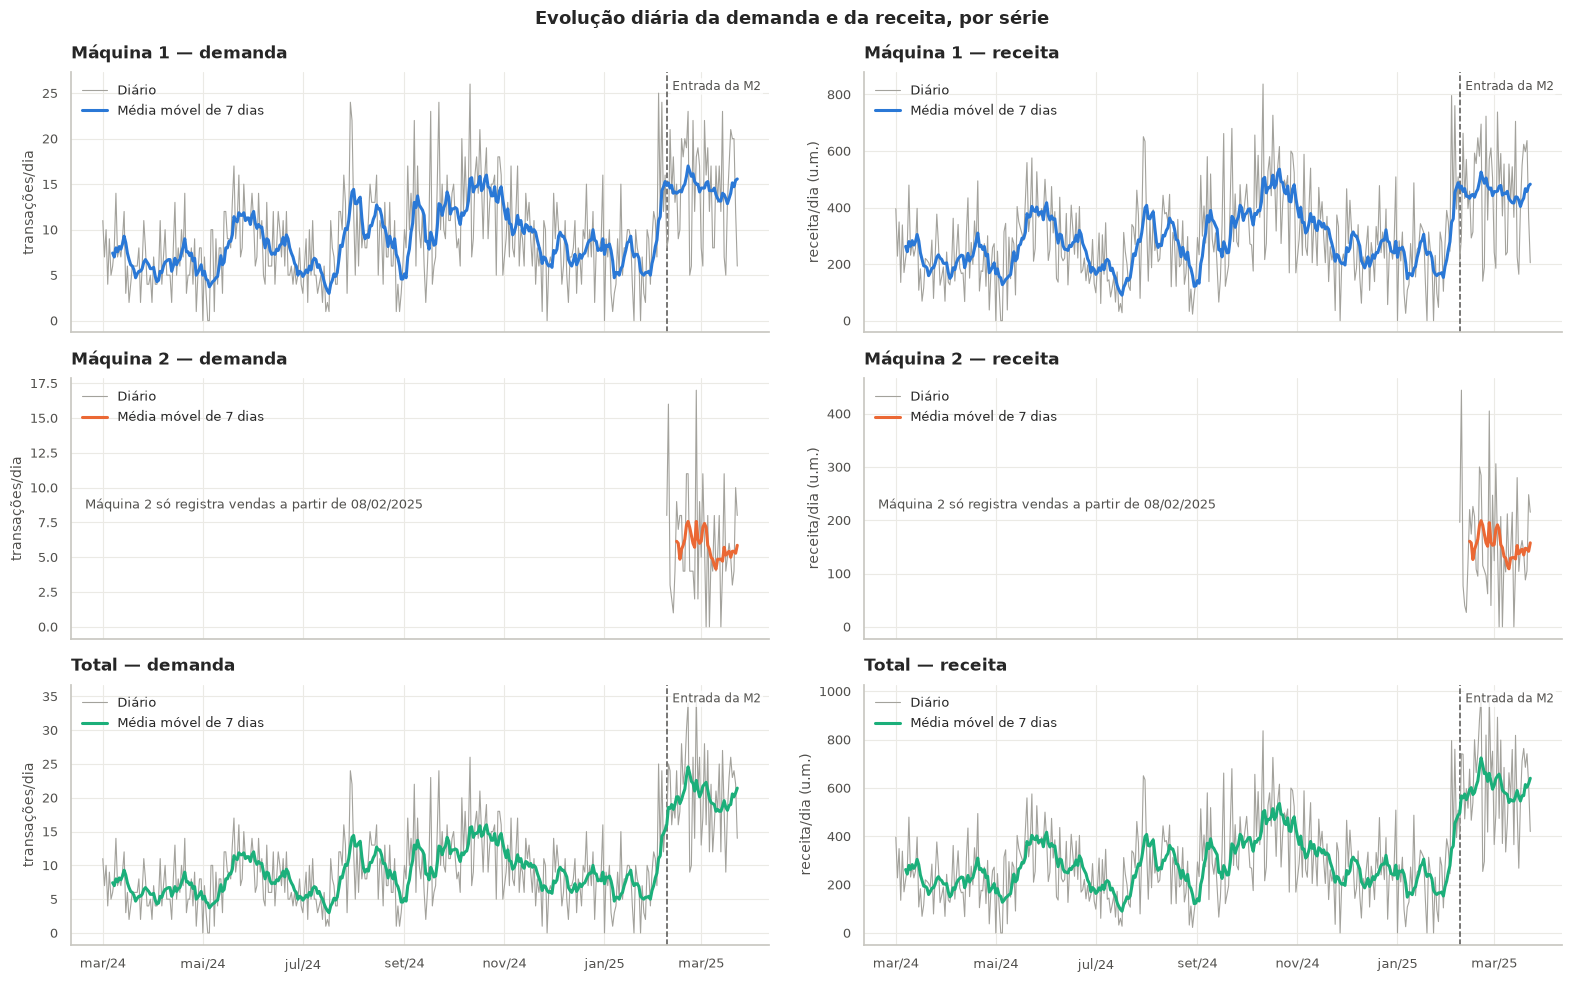

In [4]:
from src.eda.descriptive_analysis import grafico_evolucao, resumo_series
display(resumo_series(base).round(2))
mostrar(grafico_evolucao(base))

**Leitura:**
- A Máquina 1 vende em média **9,4 transações/dia** (≈ 297 u.m./dia, ticket de 31,8), mas o nível muda bastante ao longo do ano: de ~5/dia em jun/2024 a ~15/dia em fev–mar/2025.
- A razão variância/média da demanda (~2,9) indica **sobredispersão bruta**. O notebook 02 mostra que ela vem principalmente de mudanças de nível e do padrão semanal, e não de ruído extra.
- A Máquina 2 vende ~6/dia, com ticket menor (26,3).
- O Total salta em fev/2025 por **dois motivos sobrepostos**: a M1 sobe de patamar (~7 → ~14/dia, a partir de 30/01) e a M2 entra (08/02). O notebook 03 separa os dois.

## 3. `index_2` é outra máquina ou repete vendas de `index_1`?

Reaproveitamento **sem alterar a metodologia** do notebook `teste_index2_nova_maquina.ipynb` (raiz do diretório), agora organizado na classe `IdentificacaoMaquinas`.

| | Hipótese | O que prevê |
|---|---|---|
| **H_dup** | `index_2` repete vendas de `index_1` (cópia, outro fuso, datas deslocadas, preços convertidos) | casamentos de horário e produto acima do acaso, pico ao deslocar o relógio, subconjunto, razão de preços constante, volumes correlacionados |
| **H_nova** | outra fonte de vendas | tudo no nível do acaso; cardápio, preços, pagamento e horários próprios |

A nula central é o **deslocamento circular de dias**: mover os horários de `index_2` em k dias preserva o perfil intradiário e o volume, mas destrói qualquer pareamento real. Um **controle positivo** planta cópias para provar que os testes teriam poder. A mesma semente do original reproduz os mesmos números (execução ≈ 1 min).

In [5]:
from src.structural_breaks.machine_identification import IdentificacaoMaquinas

idm = IdentificacaoMaquinas(base.transacoes)
sintese = idm.executar()
display(sintese.style.format({"p": "{:.3g}", "p (Holm)": "{:.3g}"}, na_rep="—").hide(axis="index"))

2026-11-10 19:09:06 | INFO    | src.structural_breaks.machine_identification | Identificação das máquinas: período comum 08/02/2025 a 23/03/2025 (44 dias)


2026-11-10 19:10:02 | INFO    | src.structural_breaks.machine_identification | Identificação concluída: 13/13 testes favorecem H_nova; nenhum favorece H_dup


teste,observado,H0 do teste,p,favorece,p (Holm)
"4. Casamentos, mesmo produto, ±60 s",0 de 262 (acaso ≈ 0.6),acaso,1,H_nova (nada acima do acaso),1
"4. Casamentos, qualquer produto, ±5 s",2 (acaso ≈ 0.9),acaso,0.273,H_nova (nada acima do acaso),1
4. Datas deslocadas (k dias),máximo 2 casamentos (k = 10); mediana 0,—,—,H_nova (sem pico),—
5. Relógio deslocado (−12 h a +12 h),máx. 4 em -113 min; máximos nulos 3–6,acaso,0.75,H_nova (nada acima do acaso),1
"5. Relógio deslocado, qualquer produto",máx. 17 em -169 min; máximos nulos 15–21,acaso,0.818,H_nova (nada acima do acaso),1
6. Subconjunto,23 violações em produtos comuns; 55% das vendas com produto inexistente em index_1,—,—,H_nova (critério determinístico),—
7. Preços,razões 0.81–0.96 (CV 8%),—,—,H_nova (sem fator único),—
8. Pagamento em dinheiro,index_1 0% × index_2 31%,proporções iguais,8.94e-48,H_nova,8.05e-47
9. Mesmo equipamento físico,3 pares < 24 s (acaso ≈ 3.8),—,—,H_nova (evidência fraca),—
10. Volume diário,ρ = -0.11,ρ = 0,0.818,H_nova (sem dependência),1


**Formato do registro**

,index_1,index_2
colunas com identificador de cartão,sim,não
horários com milissegundos,100%,0%
preços com centavos,100%,0%
preços distintos,4,10
produtos distintos,8,30
% em dinheiro (cash),0%,31%
horários repetidos (grupos),0,7
registros nesses grupos,0,15
menor intervalo entre vendas (s),39.500,0.000


**Controle positivo: os testes detectariam uma cópia?** (deslocamento plantado: −180 min)

,fração copiada,registros copiados,máximo da varredura,deslocamento do máximo (min),faixa dos máximos nulos,p,detectado no deslocamento plantado
0,2%,5,5,-180,3–6,0.182,True
1,5%,13,13,-180,3–6,0.023,True
2,10%,26,26,-180,3–6,0.023,True


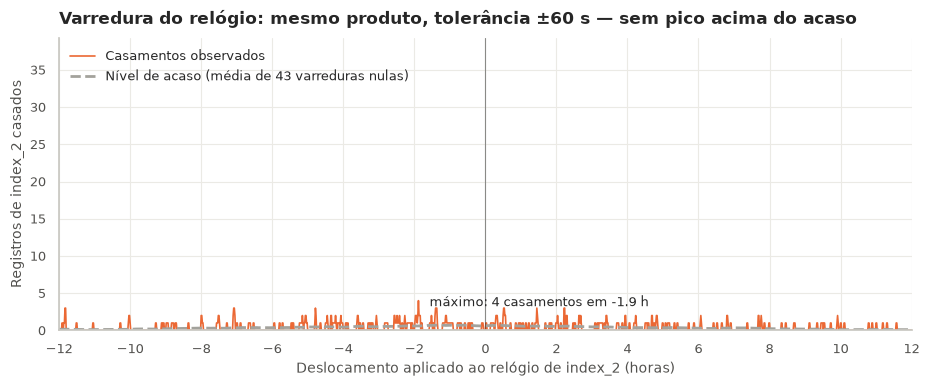

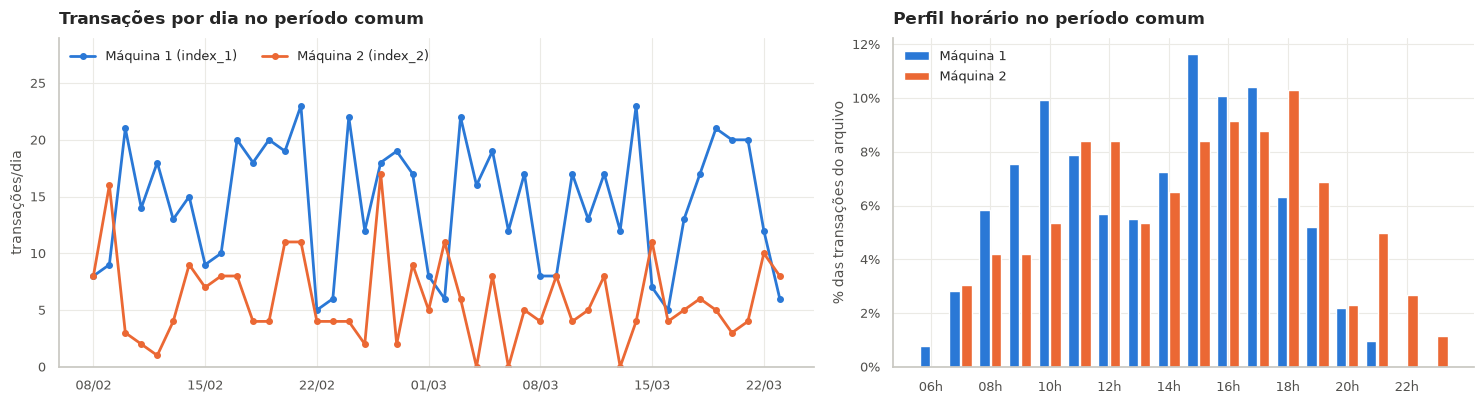

In [6]:
display(Markdown("**Formato do registro**"))
display(idm.resultados["formato"])
display(Markdown("**Controle positivo: os testes detectariam uma cópia?** (deslocamento plantado: −180 min)"))
display(idm.resultados["controle_positivo"])
mostrar(idm.grafico_varredura())
mostrar(idm.grafico_perfis())

### Conclusão da identificação

**`index_2.csv` não repete vendas de `index_1.csv`.** Os 13 testes apontam na mesma direção:

1. **Não há pareamento.** São 0 de 262 vendas com o mesmo produto em ±60 s (o acaso daria ~0,6), e nenhum pico em deslocamentos de relógio de −12 h a +12 h (p = 0,75).
2. **Os testes tinham poder.** Uma cópia de apenas 5% dos registros (13 vendas) é detectada exatamente no deslocamento plantado, com o menor p possível.
3. **Não é subconjunto.** 55% das vendas da M2 são de produtos que a M1 nunca vendeu, e há 23 violações dia × produto.
4. **Não é conversão.** Não há fator único de preço (razões de 0,81 a 0,96). A M2 tem 31% de vendas em dinheiro; a M1, 0% desde jul/2024.
5. **As operações são independentes.** ρ = −0,11 nas vendas diárias (p circular = 0,82), e os perfis horário e semanal são próprios (p < 0,001 com o dia como unidade).

**Implicação:** modelar a Máquina 2 separadamente e somar as duas no Total **não conta a mesma venda duas vezes**.

**Limitação:** a análise não diz se a M2 é uma máquina automática ou um caixa/PDV (os pedidos com vários itens sugerem PDV), nem se as duas ficam no mesmo local.